# Touré and the "greatest midfielders" conversation

Career Premier League totals (appearances, goals, assists) for the midfielders who usually make the all-time lists,
from the public stats API behind premierleague.com, saved in `data/external/pl_career_midfield_greats.csv` with each
player's league titles and Premier League Hall of Fame year (Wikipedia).

Roy Keane isn't included: the API has no career record for players who retired before 2010.

**Read with care.** Goals and assists per appearance favour attacking midfielders. They say nothing about what Vieira,
Carrick or Kanté were in the team to do, so this is a check on one claim (that Touré's output doesn't belong in the
conversation), not a ranking.

In [1]:
from pathlib import Path
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#6CABDD", "#1C2C5B", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad"
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2013 -> '2013/14'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2017/18 (official Opta stats)."""
    d = pd.read_csv(EXT / "pl_midfielders_2010-2018.csv")
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["passes90"] = p90(d.totalPasses)
    d["pass_pct"] = 1 - d.totalUnsuccessfulPassesExclCrossesAndCorners / d.totalPasses
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
YAYA = "Yaya Touré"

In [2]:
G = pd.read_csv(EXT / "pl_career_midfield_greats.csv")
G["ga"] = G.goals + G.assists
G["ga_per_app"] = G.ga / G.appearances
G.sort_values("ga_per_app", ascending=False).round(2)

,name,player_id,appearances,goals,assists,pl_titles,hall_of_fame,ga,ga_per_app
7,Kevin De Bruyne,61366,288,72,119,6,no,191,0.66
5,David Silva,20664,309,60,93,4,no,153,0.50
6,Cesc Fàbregas,17878,350,50,111,2,no,161,0.46
2,Frank Lampard,2051,609,177,102,3,2021,279,0.46
1,Steven Gerrard,1814,504,120,92,0,2021,212,0.42
0,Yaya Touré,14664,230,62,32,3,no,94,0.41
3,Paul Scholes,363,499,107,55,11,2022,162,0.32
4,Patrick Vieira,1593,307,31,34,3,2022,65,0.21
9,Michael Carrick,2404,481,24,40,5,no,64,0.13
8,N'Golo Kanté,116594,227,12,17,2,no,29,0.13


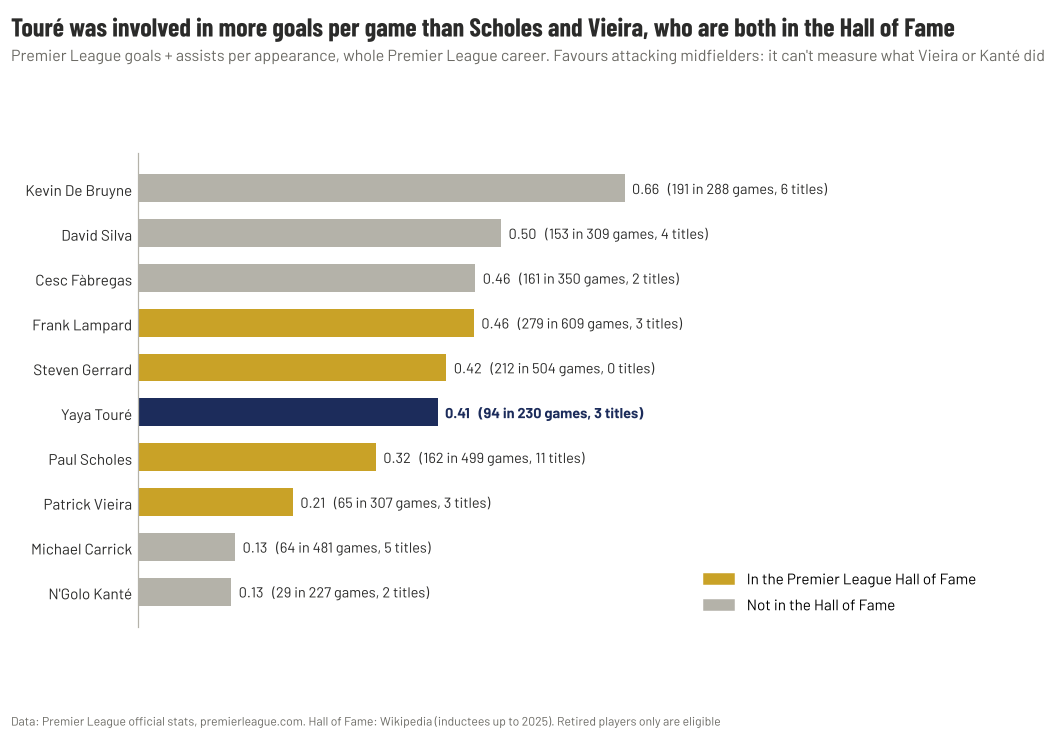

In [3]:
# Figure 11: goal involvement per appearance, with titles and Hall of Fame status
g = G.sort_values("ga_per_app")
fig, ax = plt.subplots(figsize=(10, 5.6))
yy = np.arange(len(g))
hof = g.hall_of_fame != "no"
cols = [NAVY if n == YAYA else GOLD if h else GREY for n, h in zip(g.name, hof)]
ax.barh(yy, g.ga_per_app, color=cols, height=0.62)
for yi, r in zip(yy, g.itertuples()):
    ax.text(r.ga_per_app + 0.01, yi, f"{r.ga_per_app:.2f}   ({r.ga} in {r.appearances} games, {r.pl_titles} title{'s' if r.pl_titles != 1 else ''})",
            va="center", fontsize=9.5, color=NAVY if r.name == YAYA else DARK, fontweight="bold" if r.name == YAYA else "normal")
ax.set_yticks(yy, g.name, fontsize=10)
ax.set_xlim(0, g.ga_per_app.max() * 1.75); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GOLD, label="In the Premier League Hall of Fame"), Patch(color=GREY, label="Not in the Hall of Fame")], frameon=False, loc="lower right")
y = G[G.name == YAYA].iloc[0]
above = G[(G.hall_of_fame != "no") & (G.ga_per_app < y.ga_per_app)].name.str.split().str[-1].tolist()
titles(fig, f"Touré was involved in more goals per game than {' and '.join(above)}, who are both in the Hall of Fame",
       "Premier League goals + assists per appearance, whole Premier League career. Favours attacking midfielders: it can't measure what Vieira or Kanté did",
       "Data: Premier League official stats, premierleague.com. Hall of Fame: Wikipedia (inductees up to 2025). Retired players only are eligible")
fig.savefig(FIGS / "11_the_canon.png")